# Проект - нейросеть для предсказания калорийности блюд

Данный ноутбук - развитие экспериментов `project_exp_v1`:
- основное отличие - добавление справочника калорийности ингредиентов как внешние данные
        - справочник нужно найти, обработать, сопоставить с ингредиентами и внедрить как-то в модель

- это должно помочь модели предсказывать калорийность всего блюда
    - так как задача сужается до определения массы ингредиентов в блюде
    - а в этой части серия 'Эксп_в1' дошла Mass MAE ~ 50
    - что дает надежду на общий итог предсказания калорийности тоже в райноне 50 MAE 
        - то есть достижение цели проекта

## Блок инициализации

In [2]:
# импорты
import pathlib as path
import random
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

# local scripts
import scripts.utils as utils
import scripts.models as models
import scripts.dataset as dataset
import scripts.config as config

model_config = config.MealModelConfig()

SEED = model_config.SEED

# задание случайностей - seed
utils.set_random(SEED)

DATA_PATH = path.Path('data')

## Справочник калорийности

In [114]:
import scipy.sparse as sparse

ingr_cal_mapping_df = pd.read_csv(DATA_PATH / 'nutrients' / 'processed' / 'ingr_nutr_mapping_result.csv')
ingr_cal_mapping = ingr_cal_mapping_df[['food_ingr', 'energy_kcal']]

print('Ingredients kal mapping:', ingr_cal_mapping.shape)
print(ingr_cal_mapping.head(10))

Ingredients kal mapping: (197, 2)
        food_ingr  energy_kcal
0         almonds          598
1           apple           61
2      artichokes          160
3  chayote squash           19
4        bok choy           21
5       asparagus           20
6         avocado          160
7           bacon          449
8    turkey bacon          368
9      sandwiches          231


# План экспериментов

- Эксперимент 2.1 
    - использовать последнюю модель из "Серии 1" (эксп.9/эксп.13 - диапазон MAE 64-70)
    - добавить признаки калорийности из справочника 3-им входом во fusion-слой
        - как реализовать механизм отбора конкретных слов/токенов, чтобы подать именно матрицу текущих ингредиентов, а не все подряд

- Эксперимент 2.2
    - вместо fusion слоя по новому использовать механизм кросс-внимания - между признаками-ингредиентами и признаками картинки

- Эксперимент 2.3
    - развитие идей из "Серии 1" - убрать direct target голову?

- Эксперимент 2.4
    - композиция из НС + catboost 
    - добавить табличные агрегатные признаки по справочным данным для каждого блюда
        - min/max/median/mean калорийность списка
        - количество ингредиентов
        - добавить предсказание НС (или визуальные компоненты эмбеддингов картинки)
    - запускать catboost на предсказаниях модели 


## Перезагрузка зависимостей

In [ ]:
import importlib 
import scripts.dataset as dataset
import scripts.utils as utils
import scripts.models as models
import scripts.config as config

importlib.reload(dataset)
importlib.reload(utils)
importlib.reload(models)
importlib.reload(config)

## Эксперимент 2.1 - добавление справочника калорийности
- использовать последнюю модель из "Серии 1" (эксп.9/эксп.13 - диапазон MAE 64-70)
- добавить признаки калорийности из справочника 3-им входом во fusion-слой
    - как реализовать механизм отбора конкретных слов/токенов, чтобы подать именно матрицу текущих ингредиентов, а не все подряд

### Эксперимент 2.1 - запуск на ВМ Colab (~ 1ч. 35 мин)

см. результаты в `project_exp_v2_colab.ipynb`

In [ ]:
import numpy as np
import pandas as pd
import pathlib as path
from functools import partial
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModel

# local scripts
import scripts.dataset as dataset
import scripts.utils as utils
import scripts.models as models
import scripts.config as config

config = config.MealModelConfig()

utils.set_random(config.SEED)
log = partial(utils.log_fn, config=config)

tokenizer = AutoTokenizer.from_pretrained(config.TEXT_MODEL_NAME)

train_dataset = dataset.MealDataset(model_config=config, split='train')
ingr2kal_ref_matrix, ingr_encoder = train_dataset.ingr2kal_ref_matrix, train_dataset.ingr_encoder

train_dataloader = DataLoader(dataset=train_dataset, batch_size=config.N_BATCH, shuffle=True, collate_fn=partial(dataset.collate_fn, tokenizer=tokenizer))

val_dataset = dataset.MealDataset(model_config=config, split='test', ingr2kal_ref_matrix=ingr2kal_ref_matrix, ingr_encoder=ingr_encoder)
val_dataloader = DataLoader(dataset=val_dataset, batch_size=config.N_BATCH, shuffle=False, collate_fn=partial(dataset.collate_fn, tokenizer=tokenizer))

model = models.MealModelNN(config=config) 

# разморозка параметров
utils.unfreeze_model_params(model, config)

train_params = np.sum([p.numel() for p in model.parameters() if p.requires_grad])
print(f'trainable parameters = {train_params:,d}')

# подключаем обучаемые (активные) параметры к оптимизатору

optimizer = torch.optim.AdamW([
    {'params': [p for p in model.text_model.parameters() if p.requires_grad], 'lr': config.LR_TEXT_MODEL, 'weight_decay': config.WEIGHT_DECAY},
    {'params': [p for p in model.img_model.parameters() if p.requires_grad], 'lr': config.LR_IMG_MODEL, 'weight_decay': config.WEIGHT_DECAY},

    {'params': model.text_proj.parameters(), 'lr': config.LR_PROJ, 'weight_decay': config.WEIGHT_DECAY},
    {'params': model.img_proj.parameters(), 'lr': config.LR_PROJ, 'weight_decay': config.WEIGHT_DECAY},
    {'params': model.ref_k100_proj.parameters(), 'lr': config.LR_PROJ, 'weight_decay': config.WEIGHT_DECAY},
    
    {'params': model.norm_text.parameters(), 'lr': config.LR_PROJ, 'weight_decay': config.WEIGHT_DECAY},
    {'params': model.norm_img.parameters(), 'lr': config.LR_PROJ, 'weight_decay': config.WEIGHT_DECAY},
    {'params': model.norm_ref_k100.parameters(), 'lr': config.LR_PROJ, 'weight_decay': config.WEIGHT_DECAY},

    {'params': model.fusion.parameters(), 'lr': config.LR_FUSION, 'weight_decay': config.WEIGHT_DECAY},
    {'params': model.regression_head_k_100.parameters(), 'lr': config.LR_REGRESSION_HEAD, 'weight_decay': config.WEIGHT_DECAY},
    {'params': model.regression_head_mass.parameters(), 'lr': config.LR_REGRESSION_HEAD, 'weight_decay': config.WEIGHT_DECAY},
    {'params': model.regression_head_kal.parameters(), 'lr': config.LR_REGRESSION_HEAD, 'weight_decay': config.WEIGHT_DECAY}
])

# проверка, что все активные параметры добавлены в оптимизатор
utils.optimizer_params_sanity_check(model, optimizer)

# - прогрев learning rate warmup
iters_per_epoch = len(train_dataloader)

# for real
warmup_steps = int(1.7 * iters_per_epoch)   # ≈1.7 эпохи

# for debug
#warmup_steps = 75

print(f'warmup_steps = {warmup_steps}')
scheduler = torch.optim.lr_scheduler.LambdaLR(
    optimizer,
    lr_lambda=lambda step: min(1.0, step / warmup_steps)  # 150 шагов ≈ 1.7 эпохи при BATCH=32
)

print(f'batch size = {config.N_BATCH}')
print(f'n_iter = {config.N_ITER}')
print(f'train iterations/batch = {len(train_dataloader)}')
print(f'val iterations/batch = {len(val_dataloader)}')

train_loss_history = []
train_mae_history = []
train_mae_kal_100_history = []
train_mae_mass_history = []
train_mae_direct_history = []
train_time_history = []

val_loss_history = []
val_mae_history = []
val_mae_kal_100_history = []
val_mae_mass_history = []
val_mai_direct_history = []
val_time_history = []

best_metric = 1000
best_epoch = -1
for epoch in range(config.N_EPOCHS):
    train_huber_loss, train_metric_mae, train_kal_100_mae, train_mass_mae, train_direct_mae, train_time = utils.train(model=model, config=config, optimizer=optimizer, dataloader=train_dataloader, scheduler=scheduler)
    train_loss_history.append(train_huber_loss)
    train_mae_history.append(train_metric_mae)
    train_mae_kal_100_history.append(train_kal_100_mae)
    train_mae_mass_history.append(train_mass_mae)
    train_mae_direct_history.append(train_direct_mae)
    train_time_history.append(train_time)

    val_loss_huber, val_metric_mae, val_kal_100_mae, val_mass_mae, val_direct_mae, val_time = utils.validate(model=model, config=config, dataloader=val_dataloader)
    val_loss_history.append(val_loss_huber)
    val_mae_history.append(val_metric_mae)
    val_mae_kal_100_history.append(val_kal_100_mae)
    val_mae_mass_history.append(val_mass_mae)
    val_mai_direct_history.append(val_direct_mae)
    val_time_history.append(val_time)

    print(f'epoch - {epoch}: train_loss = {train_huber_loss:.2f}/{train_time:.2f} sec, train mae = {train_metric_mae:.2f}, direct mae = {train_direct_mae:.2f}, kal_100 mae = {train_kal_100_mae:.2f}, mass mae = {train_mass_mae:.2f}, \n \
            val_loss = {val_loss_huber:.2f}/{val_time:.2f} sec, val_mae = {val_metric_mae:.2f}, direct mae = {val_direct_mae:.2f}, kal_100_mae = {val_kal_100_mae:.2f}, mass_mae = {val_mass_mae:.2f}')
       
    if val_metric_mae < best_metric:
        best_metric = val_metric_mae
        best_epoch = epoch
        utils.save_checkpoint(model, config, optimizer, scheduler, epoch, best_epoch, best_metric)

    # если метрика не уменьшается в течение config.PATIENCE эпох подряд, то останавливаем обучение
    if (epoch - best_epoch) >= config.PATIENCE:
        print(f'early stopping - metric is not increasing for [{config.PATIENCE}] epochs')
        break

    if val_metric_mae < config.TARGET_METRIC:
        print(f'!! target metric reached = {config.TARGET_METRIC}, stop training')
        break

# save train logs
log_path  = path.Path(config.MODEL_LOG_SAVE_PATH)
log_path.mkdir(exist_ok=True)

pd.DataFrame(train_loss_history, columns=['loss_huber']).to_csv(log_path / 'train_loss_history.csv', index=False)
pd.DataFrame(train_mae_history, columns=['metric_mae']).to_csv(log_path / 'train_mae_history.csv', index=False)
pd.DataFrame(train_mae_kal_100_history, columns=['metric_mae']).to_csv(log_path / 'train_mae_kal_100_history.csv', index=False)
pd.DataFrame(train_mae_mass_history, columns=['metric_mae']).to_csv(log_path / 'train_mae_mass_history.csv', index=False)
pd.DataFrame(train_mae_direct_history, columns=['metric_mae']).to_csv(log_path / 'train_mae_direct_history.csv', index=False)
pd.DataFrame(train_time_history, columns=['time']).to_csv(log_path / 'train_time_history.csv', index=False)

pd.DataFrame(val_loss_history, columns=['loss_huber']).to_csv(log_path / 'val_loss_history.csv', index=False)
pd.DataFrame(val_mae_history, columns=['metric_mae']).to_csv(log_path / 'val_mae_history.csv', index=False)
pd.DataFrame(val_mae_kal_100_history, columns=['metric_mae']).to_csv(log_path / 'val_mae_kal_100_history.csv', index=False)
pd.DataFrame(val_mae_mass_history, columns=['metric_mae']).to_csv(log_path / 'val_mae_mass_history.csv', index=False)
pd.DataFrame(val_mai_direct_history, columns=['metric_mae']).to_csv(log_path / 'val_mae_direct_history.csv', index=False)
pd.DataFrame(val_time_history, columns=['time']).to_csv(log_path / 'val_time_history.csv', index=False)

### Результат выполнения (в Colab)

```
trainable parameters = 9,587,843
warmup_steps = 146
batch size = 32
n_iter = -1
train iterations/batch = 86
val iterations/batch = 16
epoch - 0: train_loss = 0.71/1712.92 sec, train mae = 158.66, direct mae = 158.78, kal_100 mae = 66.10, mass mae = 117.07, 
             val_loss = 0.63/310.61 sec, val_mae = 143.04, direct mae = 137.68, kal_100_mae = 72.38, mass_mae = 100.97
checkpoint saving to - [data/model/best_model.pth]
epoch - 1: train_loss = 0.50/115.32 sec, train mae = 120.90, direct mae = 117.45, kal_100 mae = 60.60, mass mae = 92.88, 
             val_loss = 0.40/17.84 sec, val_mae = 100.84, direct mae = 96.69, kal_100_mae = 63.28, mass_mae = 70.68
checkpoint saving to - [data/model/best_model.pth]
epoch - 2: train_loss = 0.34/118.72 sec, train mae = 91.81, direct mae = 93.65, kal_100 mae = 51.57, mass mae = 68.29, 
             val_loss = 0.31/17.63 sec, val_mae = 91.01, direct mae = 87.20, kal_100_mae = 52.90, mass_mae = 63.29
checkpoint saving to - [data/model/best_model.pth]
epoch - 3: train_loss = 0.28/116.02 sec, train mae = 83.52, direct mae = 85.24, kal_100 mae = 43.64, mass mae = 64.30, 
             val_loss = 0.30/17.75 sec, val_mae = 88.05, direct mae = 85.53, kal_100_mae = 49.72, mass_mae = 60.16
checkpoint saving to - [data/model/best_model.pth]
epoch - 4: train_loss = 0.25/116.78 sec, train mae = 78.62, direct mae = 80.35, kal_100 mae = 38.18, mass mae = 60.04, 
             val_loss = 0.25/18.34 sec, val_mae = 78.56, direct mae = 77.44, kal_100_mae = 39.49, mass_mae = 63.96
checkpoint saving to - [data/model/best_model.pth]
epoch - 5: train_loss = 0.23/117.52 sec, train mae = 74.69, direct mae = 75.73, kal_100 mae = 34.40, mass mae = 59.19, 
             val_loss = 0.24/19.57 sec, val_mae = 80.80, direct mae = 77.99, kal_100_mae = 34.36, mass_mae = 64.09
epoch - 6: train_loss = 0.21/110.67 sec, train mae = 72.58, direct mae = 74.18, kal_100 mae = 32.27, mass mae = 57.70, 
             val_loss = 0.23/17.52 sec, val_mae = 76.76, direct mae = 76.05, kal_100_mae = 33.55, mass_mae = 55.14
checkpoint saving to - [data/model/best_model.pth]
epoch - 7: train_loss = 0.19/117.00 sec, train mae = 67.79, direct mae = 69.48, kal_100 mae = 30.18, mass mae = 54.01, 
             val_loss = 0.21/18.46 sec, val_mae = 74.39, direct mae = 73.94, kal_100_mae = 29.79, mass_mae = 54.26
checkpoint saving to - [data/model/best_model.pth]
epoch - 8: train_loss = 0.18/117.23 sec, train mae = 66.36, direct mae = 67.64, kal_100 mae = 28.52, mass mae = 52.92, 
             val_loss = 0.23/17.26 sec, val_mae = 76.05, direct mae = 77.28, kal_100_mae = 30.38, mass_mae = 55.77
epoch - 9: train_loss = 0.18/108.22 sec, train mae = 66.76, direct mae = 68.39, kal_100 mae = 26.75, mass mae = 53.62, 
             val_loss = 0.22/17.96 sec, val_mae = 82.74, direct mae = 79.61, kal_100_mae = 27.20, mass_mae = 60.57
epoch - 10: train_loss = 0.17/108.51 sec, train mae = 64.58, direct mae = 65.73, kal_100 mae = 26.64, mass mae = 51.31, 
             val_loss = 0.20/17.44 sec, val_mae = 74.54, direct mae = 74.19, kal_100_mae = 28.85, mass_mae = 51.68
epoch - 11: train_loss = 0.16/107.76 sec, train mae = 63.78, direct mae = 64.65, kal_100 mae = 26.33, mass mae = 50.08, 
             val_loss = 0.19/17.39 sec, val_mae = 69.54, direct mae = 69.62, kal_100_mae = 27.73, mass_mae = 50.25
checkpoint saving to - [data/model/best_model.pth]
epoch - 12: train_loss = 0.16/114.41 sec, train mae = 61.14, direct mae = 62.13, kal_100 mae = 24.54, mass mae = 49.90, 
             val_loss = 0.18/17.66 sec, val_mae = 68.75, direct mae = 68.67, kal_100_mae = 27.41, mass_mae = 49.32
checkpoint saving to - [data/model/best_model.pth]
epoch - 13: train_loss = 0.16/115.72 sec, train mae = 60.97, direct mae = 62.37, kal_100 mae = 24.93, mass mae = 50.10, 
             val_loss = 0.18/17.60 sec, val_mae = 67.84, direct mae = 68.37, kal_100_mae = 25.18, mass_mae = 49.55
checkpoint saving to - [data/model/best_model.pth]
epoch - 14: train_loss = 0.14/118.14 sec, train mae = 59.69, direct mae = 61.23, kal_100 mae = 23.78, mass mae = 47.34, 
             val_loss = 0.18/17.49 sec, val_mae = 70.12, direct mae = 69.15, kal_100_mae = 25.63, mass_mae = 50.49
epoch - 15: train_loss = 0.14/109.84 sec, train mae = 59.90, direct mae = 61.14, kal_100 mae = 23.27, mass mae = 48.05, 
             val_loss = 0.17/17.70 sec, val_mae = 66.83, direct mae = 66.54, kal_100_mae = 25.00, mass_mae = 47.75
checkpoint saving to - [data/model/best_model.pth]
epoch - 16: train_loss = 0.14/114.60 sec, train mae = 59.44, direct mae = 60.48, kal_100 mae = 22.92, mass mae = 48.41, 
             val_loss = 0.18/17.54 sec, val_mae = 69.27, direct mae = 68.79, kal_100_mae = 25.57, mass_mae = 52.03
epoch - 17: train_loss = 0.14/111.86 sec, train mae = 58.09, direct mae = 58.88, kal_100 mae = 23.34, mass mae = 47.60, 
             val_loss = 0.17/18.04 sec, val_mae = 68.05, direct mae = 66.65, kal_100_mae = 29.25, mass_mae = 47.10
epoch - 18: train_loss = 0.13/112.04 sec, train mae = 57.24, direct mae = 58.41, kal_100 mae = 23.56, mass mae = 45.63, 
             val_loss = 0.18/17.51 sec, val_mae = 68.39, direct mae = 68.34, kal_100_mae = 24.94, mass_mae = 47.58
epoch - 19: train_loss = 0.13/111.81 sec, train mae = 55.76, direct mae = 57.17, kal_100 mae = 22.46, mass mae = 46.02, 
             val_loss = 0.16/17.71 sec, val_mae = 65.31, direct mae = 65.18, kal_100_mae = 25.29, mass_mae = 46.26
checkpoint saving to - [data/model/best_model.pth]
epoch - 20: train_loss = 0.13/117.61 sec, train mae = 55.76, direct mae = 57.03, kal_100 mae = 21.22, mass mae = 44.86, 
             val_loss = 0.18/18.19 sec, val_mae = 68.96, direct mae = 68.69, kal_100_mae = 25.69, mass_mae = 47.65
epoch - 21: train_loss = 0.13/110.77 sec, train mae = 55.68, direct mae = 56.46, kal_100 mae = 21.82, mass mae = 45.50, 
             val_loss = 0.17/18.44 sec, val_mae = 67.32, direct mae = 66.79, kal_100_mae = 22.20, mass_mae = 47.76
epoch - 22: train_loss = 0.12/109.76 sec, train mae = 52.56, direct mae = 53.61, kal_100 mae = 21.48, mass mae = 43.62, 
             val_loss = 0.16/18.07 sec, val_mae = 65.13, direct mae = 64.86, kal_100_mae = 23.55, mass_mae = 44.09
checkpoint saving to - [data/model/best_model.pth]
epoch - 23: train_loss = 0.12/116.77 sec, train mae = 52.56, direct mae = 54.07, kal_100 mae = 21.45, mass mae = 43.15, 
             val_loss = 0.15/17.52 sec, val_mae = 63.86, direct mae = 63.33, kal_100_mae = 22.78, mass_mae = 45.46
checkpoint saving to - [data/model/best_model.pth]
epoch - 24: train_loss = 0.12/115.93 sec, train mae = 53.33, direct mae = 54.58, kal_100 mae = 21.31, mass mae = 44.21, 
             val_loss = 0.16/17.58 sec, val_mae = 65.35, direct mae = 65.31, kal_100_mae = 21.82, mass_mae = 45.35
epoch - 25: train_loss = 0.12/108.86 sec, train mae = 52.44, direct mae = 53.63, kal_100 mae = 20.37, mass mae = 43.25, 
             val_loss = 0.16/17.18 sec, val_mae = 66.01, direct mae = 65.30, kal_100_mae = 23.64, mass_mae = 45.86
epoch - 26: train_loss = 0.12/108.26 sec, train mae = 52.49, direct mae = 53.99, kal_100 mae = 20.55, mass mae = 42.58, 
             val_loss = 0.15/17.73 sec, val_mae = 64.19, direct mae = 62.88, kal_100_mae = 21.43, mass_mae = 44.30
epoch - 27: train_loss = 0.11/107.57 sec, train mae = 51.33, direct mae = 52.93, kal_100 mae = 20.82, mass mae = 42.32, 
             val_loss = 0.16/17.47 sec, val_mae = 63.23, direct mae = 62.96, kal_100_mae = 23.51, mass_mae = 43.49
checkpoint saving to - [data/model/best_model.pth]
epoch - 28: train_loss = 0.11/112.28 sec, train mae = 51.02, direct mae = 52.17, kal_100 mae = 20.46, mass mae = 43.22, 
             val_loss = 0.16/17.71 sec, val_mae = 64.13, direct mae = 63.95, kal_100_mae = 21.04, mass_mae = 43.76
training: 100%|██████████| 86/86 [01:48<00:00,  1.26s/it]
validation: 100%|██████████| 16/16 [00:17<00:00,  1.10s/it]
epoch - 29: train_loss = 0.11/108.17 sec, train mae = 50.45, direct mae = 51.54, kal_100 mae = 20.38, mass mae = 41.68, 
             val_loss = 0.16/17.56 sec, val_mae = 66.34, direct mae = 65.64, kal_100_mae = 21.95, mass_mae = 44.20
```

#### График обучения

Text(0.5, 1.0, 'MAE')

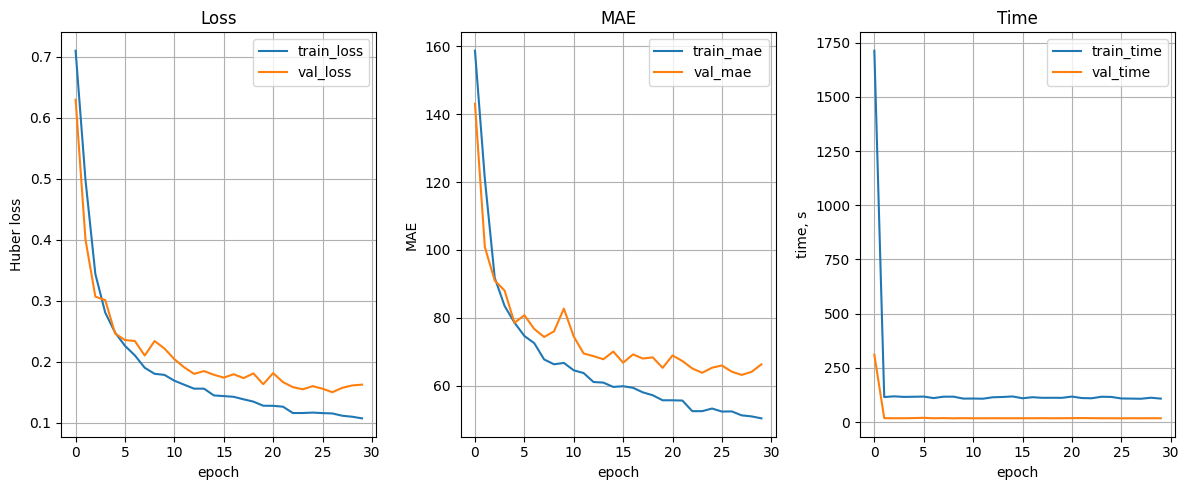

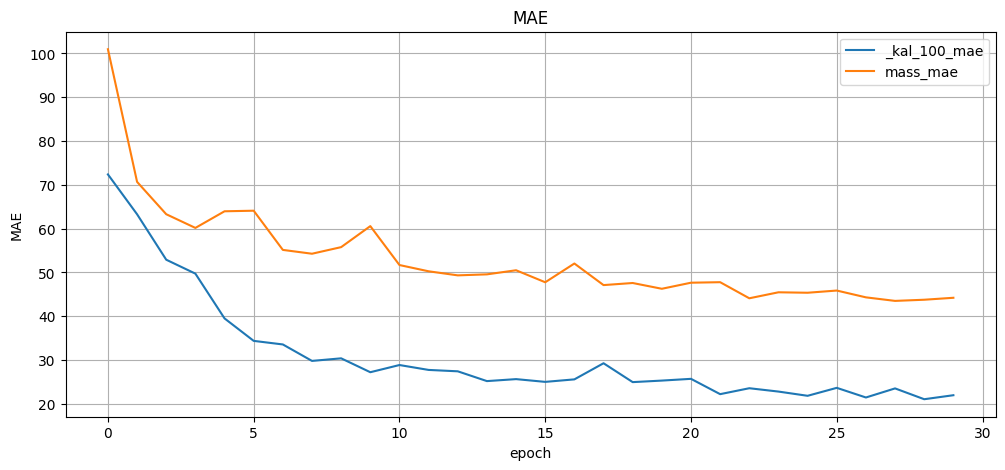

In [20]:
import pathlib as path
import pandas as pd
import matplotlib.pyplot as plt

import scripts.config as cfg
import scripts.utils

config = cfg.MealModelConfig()

log_path  = path.Path(config.MODEL_LOG_SAVE_PATH) / 'experiments-v2' / 'exp-2.1' / 'colab'
train_loss_history = pd.read_csv(log_path /  'train_loss_history.csv')
train_mae_history = pd.read_csv(log_path / 'train_mae_history.csv')
train_time_history = pd.read_csv(log_path / 'train_time_history.csv')

val_loss_history = pd.read_csv(log_path / 'val_loss_history.csv')
val_mae_history = pd.read_csv(log_path / 'val_mae_history.csv')
val_time_history = pd.read_csv(log_path / 'val_time_history.csv')

utils.plof_train_log(train_loss_history, val_loss_history, train_mae_history, val_mae_history, train_time_history, val_time_history)

val_mae_kal_100_history = pd.read_csv(log_path / 'val_mae_kal_100_history.csv')
val_mae_mass_history = pd.read_csv(log_path / 'val_mae_mass_history.csv')

fix, axs = plt.subplots(1,1, figsize=(12,5))
ax=axs
ax.plot(val_mae_kal_100_history)
ax.plot(val_mae_mass_history)
ax.grid();ax.set_xlabel('epoch');ax.set_ylabel('MAE');ax.legend(['_kal_100_mae', 'mass_mae'])
ax.set_title('MAE')

Достигнут предсказанный предел в 63-66 MAE
 - новый справочник калорий не сильно помог
 - проблема остается недостаточном использовании картинки и кросс-внимании на признаках ингредиентов
 - поэтому необходим новый подход с кросс-вниманием текста и картинки

### Эксперимент 2-next (TODO)
- реализовано кросс-модальное внимание текстовых токенов-ингредиентов и эмбеддингов картики
    - использование единственного CLS-токена приведет тому, что seq_len в механизме внимания равен 1, это приводит к простому усреднению признаков картинки (Global Attention Pooling), вместо самого механизма внимания
        - модель не сможет сопоставить конкретный ингредиент с его областью на фото
        - это было уже использовано в Эксп. 0, и вся дальнейшая работа строилась вместо внимания на fusion (конкатенации) эмбеддингов текста и картинки
            - однако fusion похоже себя исчерпал, хоть модель и сходиться медленно в сторону 60 MAE на test, на train модель смогла достигнуть 50 MAE, переобучение начало усиливаться и далее нужна дополнительная регялирация или аугментация
- в механизм query внимания необходимо подать последовательность токенов ингредиентов [Batch, K, D_model]:
    - text_emb - взять у DistilBERT mean pooling по субтокенам, чтобы получить вектор [1, 768]
    - prop_emb - физические признаки ингредиентов (калорийность, опциаонально - плотность, БЖУ (зависит от доступности справочника)) - пропускается через nn.Linear(num_props, D_props)
    - объединение concat(text_emb, prop_emb) -> nn.Linear -> nn.Gelu -> nn.LayerNorm - результат в размерности img_emb
- признаки картинки необходимо использовать до усреднения (global average pooling), чтобы иметь набор пространственных признаков
    - использовать пространственную карту признаков на выходном слое до пулинга [Batch, 960, 14, 14]
    - развернуть размерности в вид [Batch, 196, 960] - так получится последовательность из 196 векторов, каждый из которых отвечает за свою область на картинке
- механизм кросс-внимания
    - Query - [Batch, K, D_model] - ингредиенты (с учетом маски, для выравнивания длины в батче)
    - Key, Value - [Batch, 196, 960] - 196 пространственных региона изображения
    - в результате, каждый токен (ингредиент) просканирует все области изображения и извлечет информацию о размере, и том как он выглядит
- выход (голова)
    - выход внимания [Batch, K, D_model] - через nn.Linear(D_model, 1) - получаем K-логитов z1,..,zk
    - маскируем паддинг ингредиенты и применяем Softmax для получения доли веса p1,...,pk
    - считаем итоговые калории
        - pred_kal = M_total x Sum(pi * kal/100)

# СТОП - у нас есть масса блюда - а сейчас я ее предсказываю, а не использую как готовую - это все меняет!

## Эксперимент 2.2 - используем массу как число в тектсе как подсказка
- не использована масса блюда как признак 
    - быстрая проверка - не меняю архитектуру 
    - просто добавить подсказку с массой в текст и продолжить предсказывать и массу и калорийность

In [ ]:
import numpy as np
import pandas as pd
import pathlib as path
from functools import partial
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModel

# local scripts
import scripts.dataset as dataset
import scripts.utils as utils
import scripts.models as models
import scripts.config as config

config = config.MealModelConfig()

utils.set_random(config.SEED)
log = partial(utils.log_fn, config=config)

tokenizer = AutoTokenizer.from_pretrained(config.TEXT_MODEL_NAME)

train_dataset = dataset.MealDataset(model_config=config, split='train')
ingr2kal_ref_matrix, ingr_encoder = train_dataset.ingr2kal_ref_matrix, train_dataset.ingr_encoder

train_dataloader = DataLoader(dataset=train_dataset, batch_size=config.N_BATCH, shuffle=True, collate_fn=partial(dataset.collate_fn, tokenizer=tokenizer))

val_dataset = dataset.MealDataset(model_config=config, split='test', ingr2kal_ref_matrix=ingr2kal_ref_matrix, ingr_encoder=ingr_encoder)
val_dataloader = DataLoader(dataset=val_dataset, batch_size=config.N_BATCH, shuffle=False, collate_fn=partial(dataset.collate_fn, tokenizer=tokenizer))

model = models.MealModelNN(config=config) 

# разморозка параметров
utils.unfreeze_model_params(model, config)

train_params = np.sum([p.numel() for p in model.parameters() if p.requires_grad])
print(f'trainable parameters = {train_params:,d}')

# подключаем обучаемые (активные) параметры к оптимизатору

optimizer = torch.optim.AdamW([
    {'params': [p for p in model.text_model.parameters() if p.requires_grad], 'lr': config.LR_TEXT_MODEL, 'weight_decay': config.WEIGHT_DECAY},
    {'params': [p for p in model.img_model.parameters() if p.requires_grad], 'lr': config.LR_IMG_MODEL, 'weight_decay': config.WEIGHT_DECAY},

    {'params': model.text_proj.parameters(), 'lr': config.LR_PROJ, 'weight_decay': config.WEIGHT_DECAY},
    {'params': model.img_proj.parameters(), 'lr': config.LR_PROJ, 'weight_decay': config.WEIGHT_DECAY},
    {'params': model.ref_k100_proj.parameters(), 'lr': config.LR_PROJ, 'weight_decay': config.WEIGHT_DECAY},
    
    {'params': model.norm_text.parameters(), 'lr': config.LR_PROJ, 'weight_decay': config.WEIGHT_DECAY},
    {'params': model.norm_img.parameters(), 'lr': config.LR_PROJ, 'weight_decay': config.WEIGHT_DECAY},
    {'params': model.norm_ref_k100.parameters(), 'lr': config.LR_PROJ, 'weight_decay': config.WEIGHT_DECAY},

    {'params': model.fusion.parameters(), 'lr': config.LR_FUSION, 'weight_decay': config.WEIGHT_DECAY},
    {'params': model.regression_head_k_100.parameters(), 'lr': config.LR_REGRESSION_HEAD, 'weight_decay': config.WEIGHT_DECAY},
    {'params': model.regression_head_mass.parameters(), 'lr': config.LR_REGRESSION_HEAD, 'weight_decay': config.WEIGHT_DECAY},
    {'params': model.regression_head_kal.parameters(), 'lr': config.LR_REGRESSION_HEAD, 'weight_decay': config.WEIGHT_DECAY}
])

# проверка, что все активные параметры добавлены в оптимизатор
utils.optimizer_params_sanity_check(model, optimizer)

# - прогрев learning rate warmup
iters_per_epoch = len(train_dataloader)

# for real
warmup_steps = int(1.7 * iters_per_epoch)   # ≈1.7 эпохи

# for debug
#warmup_steps = 75

print(f'warmup_steps = {warmup_steps}')
scheduler = torch.optim.lr_scheduler.LambdaLR(
    optimizer,
    lr_lambda=lambda step: min(1.0, step / warmup_steps)  # 150 шагов ≈ 1.7 эпохи при BATCH=32
)

print(f'batch size = {config.N_BATCH}')
print(f'n_iter = {config.N_ITER}')
print(f'train iterations/batch = {len(train_dataloader)}')
print(f'val iterations/batch = {len(val_dataloader)}')

train_loss_history = []
train_mae_history = []
train_mae_kal_100_history = []
train_mae_mass_history = []
train_mae_direct_history = []
train_time_history = []

val_loss_history = []
val_mae_history = []
val_mae_kal_100_history = []
val_mae_mass_history = []
val_mai_direct_history = []
val_time_history = []

best_metric = 1000
best_epoch = -1
for epoch in range(config.N_EPOCHS):
    train_huber_loss, train_metric_mae, train_kal_100_mae, train_mass_mae, train_direct_mae, train_time = utils.train(model=model, config=config, optimizer=optimizer, dataloader=train_dataloader, scheduler=scheduler)
    train_loss_history.append(train_huber_loss)
    train_mae_history.append(train_metric_mae)
    train_mae_kal_100_history.append(train_kal_100_mae)
    train_mae_mass_history.append(train_mass_mae)
    train_mae_direct_history.append(train_direct_mae)
    train_time_history.append(train_time)

    val_loss_huber, val_metric_mae, val_kal_100_mae, val_mass_mae, val_direct_mae, val_time = utils.validate(model=model, config=config, dataloader=val_dataloader)
    val_loss_history.append(val_loss_huber)
    val_mae_history.append(val_metric_mae)
    val_mae_kal_100_history.append(val_kal_100_mae)
    val_mae_mass_history.append(val_mass_mae)
    val_mai_direct_history.append(val_direct_mae)
    val_time_history.append(val_time)

    print(f'epoch - {epoch}: train_loss = {train_huber_loss:.2f}/{train_time:.2f} sec, train mae = {train_metric_mae:.2f}, direct mae = {train_direct_mae:.2f}, kal_100 mae = {train_kal_100_mae:.2f}, mass mae = {train_mass_mae:.2f}, \n \
            val_loss = {val_loss_huber:.2f}/{val_time:.2f} sec, val_mae = {val_metric_mae:.2f}, direct mae = {val_direct_mae:.2f}, kal_100_mae = {val_kal_100_mae:.2f}, mass_mae = {val_mass_mae:.2f}')
       
    if val_metric_mae < best_metric:
        best_metric = val_metric_mae
        best_epoch = epoch
        utils.save_checkpoint(model, config, optimizer, scheduler, epoch, best_epoch, best_metric)

    # если метрика не уменьшается в течение config.PATIENCE эпох подряд, то останавливаем обучение
    if (epoch - best_epoch) >= config.PATIENCE:
        print(f'early stopping - metric is not increasing for [{config.PATIENCE}] epochs')
        break

    if val_metric_mae < config.TARGET_METRIC:
        print(f'!! target metric reached = {config.TARGET_METRIC}, stop training')
        break

# save train logs
log_path  = path.Path(config.MODEL_LOG_SAVE_PATH)
log_path.mkdir(exist_ok=True)

pd.DataFrame(train_loss_history, columns=['loss_huber']).to_csv(log_path / 'train_loss_history.csv', index=False)
pd.DataFrame(train_mae_history, columns=['metric_mae']).to_csv(log_path / 'train_mae_history.csv', index=False)
pd.DataFrame(train_mae_kal_100_history, columns=['metric_mae']).to_csv(log_path / 'train_mae_kal_100_history.csv', index=False)
pd.DataFrame(train_mae_mass_history, columns=['metric_mae']).to_csv(log_path / 'train_mae_mass_history.csv', index=False)
pd.DataFrame(train_mae_direct_history, columns=['metric_mae']).to_csv(log_path / 'train_mae_direct_history.csv', index=False)
pd.DataFrame(train_time_history, columns=['time']).to_csv(log_path / 'train_time_history.csv', index=False)

pd.DataFrame(val_loss_history, columns=['loss_huber']).to_csv(log_path / 'val_loss_history.csv', index=False)
pd.DataFrame(val_mae_history, columns=['metric_mae']).to_csv(log_path / 'val_mae_history.csv', index=False)
pd.DataFrame(val_mae_kal_100_history, columns=['metric_mae']).to_csv(log_path / 'val_mae_kal_100_history.csv', index=False)
pd.DataFrame(val_mae_mass_history, columns=['metric_mae']).to_csv(log_path / 'val_mae_mass_history.csv', index=False)
pd.DataFrame(val_mai_direct_history, columns=['metric_mae']).to_csv(log_path / 'val_mae_direct_history.csv', index=False)
pd.DataFrame(val_time_history, columns=['time']).to_csv(log_path / 'val_time_history.csv', index=False)